# ホテル予約キャンセル予測：EDA分析

## このNotebookの目的

本Notebookでは、SQLで確認したキャンセル傾向をグラフで可視化し、複数の変数の関係を調べる。また、機械学習に使用する特徴量を検討する。

### csvファイルの読み込み・使用するライブラリ

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter


In [2]:
# notebooks/からの実行と、リポジトリ直下からの実行の両方に対応する
data_candidates = [
    Path("../data/hotel_bookings.csv"),
    Path("data/hotel_bookings.csv"),
]
DATA_PATH = next((path for path in data_candidates if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "hotel_bookings.csvが見つかりません。READMEの手順に従いdata/へ配置してください。"
    )

df = pd.read_csv(DATA_PATH)

In [3]:
df.shape

(119390, 32)

## 1. SQLで検証した結果の可視化
- SQLで行った集計の結果・仮説の結果をグラフで可視化
- ダッシュボードで使用できるグラフの作成

### Lead Timeとの関係

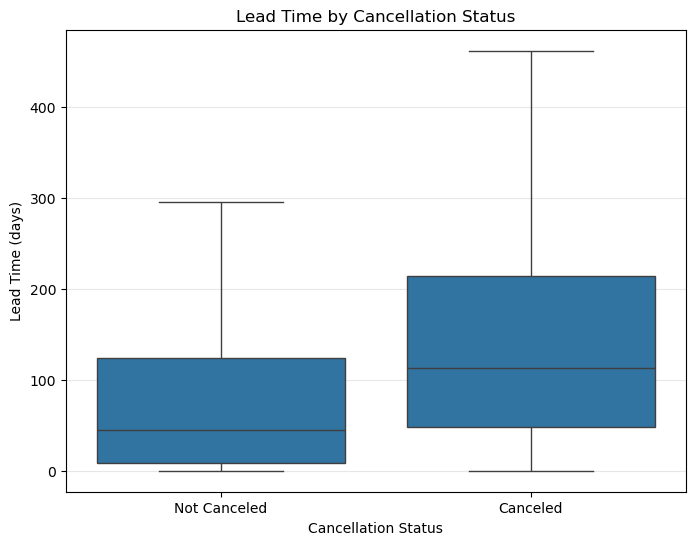

In [4]:
## is_canceledごとのlead_timeの関係
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x="is_canceled",
    y="lead_time",
    showfliers=False  # 外れ値を非表示。表示する場合は削除
)

plt.xticks([0, 1], ["Not Canceled", "Canceled"])
plt.xlabel("Cancellation Status")
plt.ylabel("Lead Time (days)")
plt.title("Lead Time by Cancellation Status")
plt.grid(axis="y", alpha=0.3)
plt.show()

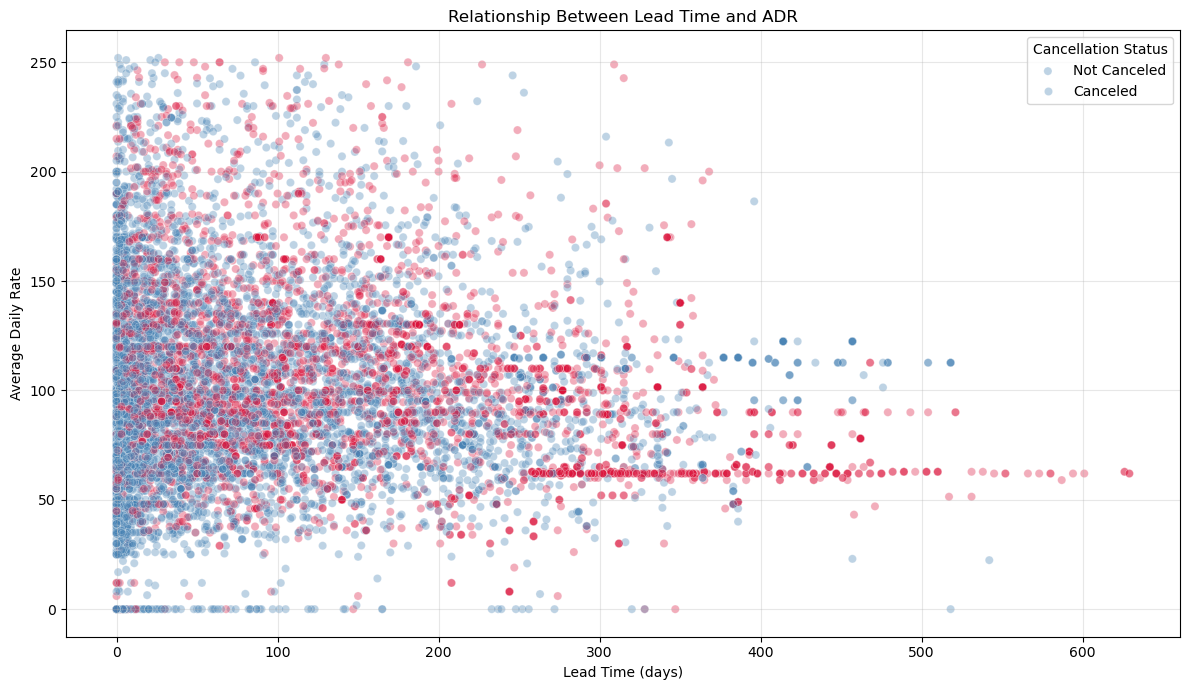

In [5]:
# 極端な外れ値を除外
plot_df = df[
    (df["lead_time"] >= 0) &
    (df["adr"] >= 0) &
    (df["adr"] <= df["adr"].quantile(0.99))
].copy()

# データが多い場合は最大10,000件を抽出
if len(plot_df) > 10000:
    plot_df = plot_df.sample(
        n=10000,
        random_state=42
    )
# 傾向が見づらくなってしまうためランダムで10000行抽出

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=plot_df,
    x="lead_time",
    y="adr",
    hue="is_canceled",
    palette={
        0: "steelblue",
        1: "crimson"
    },
    alpha=0.35,
    s=35
)

plt.xlabel("Lead Time (days)")
plt.ylabel("Average Daily Rate")
plt.title("Relationship Between Lead Time and ADR")
plt.legend(
    title="Cancellation Status",
    labels=["Not Canceled", "Canceled"]
)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 国別の関係

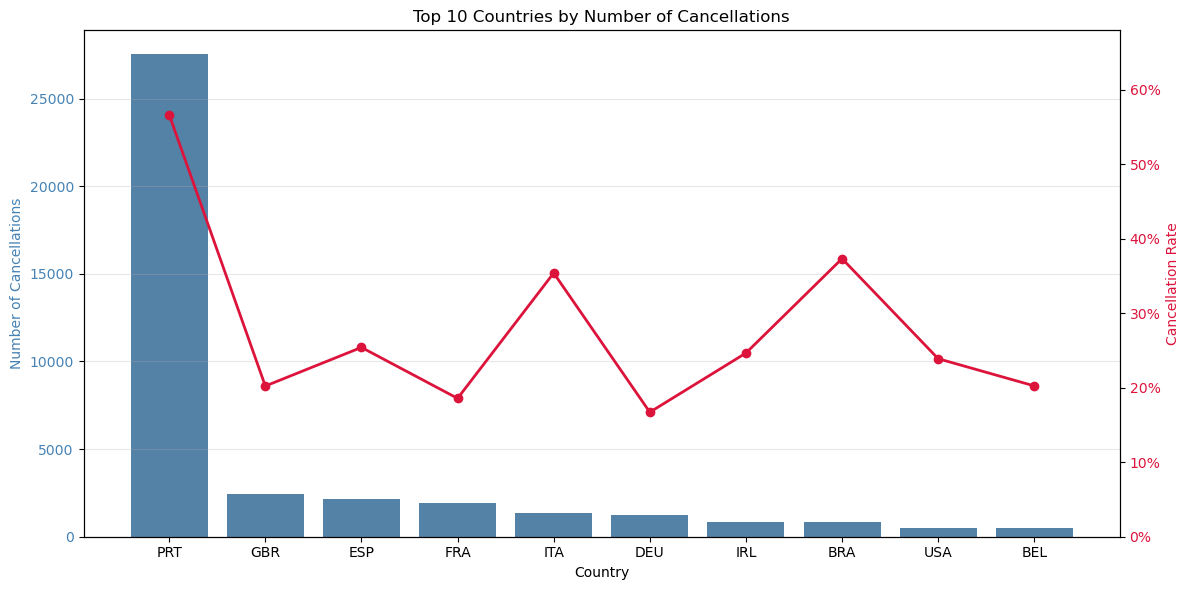

In [6]:
# 国ごとの予約数・キャンセル数を集計
country_summary = (
    df.dropna(subset=["country"])
      .groupby("country")
      .agg(
          total_bookings=("is_canceled", "size"),
          canceled_count=("is_canceled", "sum")
      )
      .assign(
          cancellation_rate=lambda x:
              x["canceled_count"] / x["total_bookings"]
      )
)

# キャンセル数が多い国 Top10
top10 = (
    country_summary
    .nlargest(10, "canceled_count")
    .sort_values("canceled_count", ascending=False)
)

# グラフ作成
fig, ax1 = plt.subplots(figsize=(12, 6))

# 棒グラフ：キャンセル数
sns.barplot(
    x=top10.index,
    y=top10["canceled_count"],
    ax=ax1,
    color="steelblue"
)

ax1.set_xlabel("Country")
ax1.set_ylabel("Number of Cancellations", color="steelblue")
ax1.tick_params(axis="y", labelcolor="steelblue")
ax1.grid(axis="y", alpha=0.3)

# 第2軸：キャンセル率
ax2 = ax1.twinx()

ax2.plot(
    range(len(top10)),
    top10["cancellation_rate"],
    color="crimson",
    marker="o",
    linewidth=2,
    label="Cancellation Rate"
)

ax2.set_ylabel("Cancellation Rate", color="crimson")
ax2.tick_params(axis="y", labelcolor="crimson")
ax2.yaxis.set_major_formatter(PercentFormatter(1.0))
ax2.set_ylim(0, min(1, top10["cancellation_rate"].max() * 1.2))

plt.title("Top 10 Countries by Number of Cancellations")
fig.tight_layout()
plt.show()

## セグメントとの関係

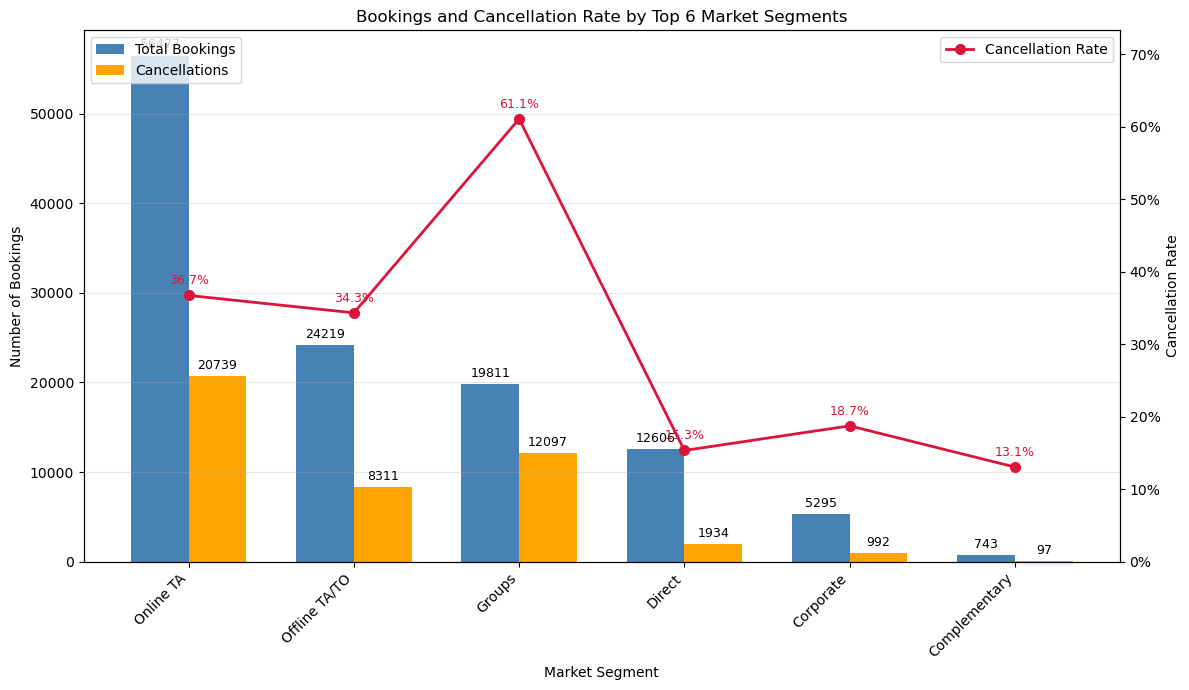

,total_bookings,canceled_count,cancellation_rate
market_segment,,,
Online TA,"56,477","20,739",36.7%
Offline TA/TO,"24,219","8,311",34.3%
Groups,"19,811","12,097",61.1%
Direct,"12,606","1,934",15.3%
Corporate,"5,295",992,18.7%
Complementary,743,97,13.1%


In [7]:
# セグメント別に予約数・キャンセル数・キャンセル率を集計
segment_summary = (
    df.dropna(subset=["market_segment"])
      .groupby("market_segment")
      .agg(
          total_bookings=("is_canceled", "size"),
          canceled_count=("is_canceled", "sum")
      )
      .assign(
          cancellation_rate=lambda x:
              x["canceled_count"] / x["total_bookings"]
      )
)

# 総予約数が多いセグメント Top6
top6_segments = (
    segment_summary
    .nlargest(6, "total_bookings")
    .sort_values("total_bookings", ascending=False)
)

# グラフ上の位置
x = np.arange(len(top6_segments))
width = 0.35

# グラフ作成
fig, ax1 = plt.subplots(figsize=(12, 7))

# 総予約数の棒グラフ
bars1 = ax1.bar(
    x - width / 2,
    top6_segments["total_bookings"],
    width,
    label="Total Bookings",
    color="steelblue"
)

# キャンセル数の棒グラフ
bars2 = ax1.bar(
    x + width / 2,
    top6_segments["canceled_count"],
    width,
    label="Cancellations",
    color="orange"
)

# 左側の軸
ax1.set_xlabel("Market Segment")
ax1.set_ylabel("Number of Bookings")
ax1.set_xticks(x)
ax1.set_xticklabels(
    top6_segments.index,
    rotation=45,
    ha="right"
)
ax1.grid(axis="y", alpha=0.3)
ax1.legend(loc="upper left")

# 棒グラフ上に件数を表示
ax1.bar_label(
    bars1,
    fmt="%d",
    padding=3,
    fontsize=9
)

ax1.bar_label(
    bars2,
    fmt="%d",
    padding=3,
    fontsize=9
)

# 右側の軸にキャンセル率を表示
ax2 = ax1.twinx()

ax2.plot(
    x,
    top6_segments["cancellation_rate"],
    color="crimson",
    marker="o",
    markersize=7,
    linewidth=2,
    label="Cancellation Rate"
)

ax2.set_ylabel("Cancellation Rate")
ax2.yaxis.set_major_formatter(PercentFormatter(1.0))

# キャンセル率の最大値に少し余白を追加
rate_upper_limit = min(
    1,
    max(0.1, top6_segments["cancellation_rate"].max() * 1.2)
)
ax2.set_ylim(0, rate_upper_limit)
ax2.legend(loc="upper right")

# 折れ線上にキャンセル率を表示
for i, rate in enumerate(top6_segments["cancellation_rate"]):
    ax2.annotate(
        f"{rate:.1%}",
        xy=(i, rate),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        color="crimson",
        fontsize=9
    )

plt.title("Bookings and Cancellation Rate by Top 6 Market Segments")
fig.tight_layout()
plt.show()

# 集計結果を表で確認
display(
    top6_segments.style.format({
        "total_bookings": "{:,.0f}",
        "canceled_count": "{:,.0f}",
        "cancellation_rate": "{:.1%}"
    })
)

## ２．まとめ

国ごとにキャンセル数の偏りが見られた。また、Lead Timeが長い予約ほどキャンセルが発生しやすい傾向が確認できた。

Lead Timeや国そのものを変えることは難しいため、キャンセルリスクの高い予約を事前に把握し、対策を行うことが有効だと考えた。

マーケットセグメントによっても予約数やキャンセル率に違いが見られた。ただし、キャンセル数だけでは比較できないため、予約数に対するキャンセル率も考慮する必要がある。

今回確認したLead Timeや国、マーケットセグメントは、キャンセル予測に関係する可能性があるため、機械学習でも特徴量として使用することを検討する。